# ทำนายน้ำท่วมรายอำเภอ: Logistic Regression, Random Forest และ XGBoost

เป้าหมายคือทำนาย `flooded` (0/1) รายอำเภอ-เดือน โดยแบ่งข้อมูลหลังสร้าง lag ตามลำดับเวลาเป็นเดือนเต็ม: **Train ≈ 70%**, **Validation ≈ 15%** สำหรับเลือกโมเดล และ **Test ≈ 15%** สำหรับประเมินครั้งสุดท้าย โดยไม่สุ่มแถวหรือให้เดือนเดียวกันปะปนข้ามชุด

- Baseline: Logistic Regression
- โมเดลเปรียบเทียบ: Random Forest Classifier และ XGBoost Classifier
- ใช้ตัวแปรสภาพอากาศและสถานะน้ำท่วมจากเดือนก่อนหน้าเท่านั้น รวมถึงฤดูกาลและอำเภอ
- ตัดตัวแปรน้ำท่วมของเดือนเป้าหมาย เช่น `flood_status`, `max_flood_ha` และจำนวนเหตุการณ์เดือนปัจจุบันออก เพื่อป้องกัน target leakage
- เปรียบเทียบ Recall, F1, PR-AUC, ROC-AUC และ Balanced Accuracy เพราะคลาสน้ำท่วมไม่ได้มีสัดส่วนเท่ากัน

ข้อมูลต้นทางครอบคลุมปี 2020–2025 หลังสร้าง lag จะแบ่งเดือนตามลำดับเวลาเป็น Train ≈ 70%, Validation ≈ 15% และ Test ≈ 15% ข้อมูลทดสอบเป็นช่วงเวลาท้ายที่กันไว้ ไม่ใช่หลักฐานยืนยันประสิทธิภาพทุกปีหรือคำเตือนรายวัน

The model uses previous month CMEMS sea-level mean as a lagged feature. Missing sea-level measurements are passed to the existing median imputer.

## 1. โหลดและตรวจข้อมูลรวม

อ่านไฟล์ที่รวมข้อมูลรายเดือนแล้ว ตรวจคอลัมน์เป้าหมาย ขนาดข้อมูล และสัดส่วนคลาส

In [85]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

filename = 'NST_merged_clean_data_2020_2025.csv'
root = next((path for path in [Path.cwd(), *Path.cwd().parents]
             if (path / 'merge_dataset' / filename).is_file()), None)
if root is None:
    raise FileNotFoundError(f'ไม่พบไฟล์ merge_dataset/{filename}')

data_path = root / 'merge_dataset' / filename
data = pd.read_csv(data_path, parse_dates=['month_start'])
data['sea_level_monthly_mean'] = data['sea_level_ssh_cmems_mean_m']
required = ['district', 'district_code', 'year', 'month', 'flooded', 'monthly_rain_total_mm',
            'monthly_rain_daily_max_mm', 'humidity_mean_rh_pct', 'humidity_mean_temp_c',
            'sea_level_monthly_mean']
missing_columns = sorted(set(required) - set(data.columns))
if missing_columns:
    raise ValueError(f'คอลัมน์ที่จำเป็นหายไป: {missing_columns}')
required_non_null = ['district', 'district_code', 'year', 'month', 'flooded', 'monthly_rain_total_mm',
                      'monthly_rain_daily_max_mm', 'month_start']
if data[required_non_null].isna().any().any():
    raise ValueError('Missing values in required model fields')
if sorted(data['year'].unique().tolist()) != list(range(2020, 2026)):
    raise ValueError('ข้อมูลต้องครอบคลุมปี 2020 ถึง 2025')
print('Missing humidity monthly values handled by lag-row filtering:', int(data['humidity_mean_rh_pct'].isna().sum()))
print('Missing CMEMS sea-level values passed to the lag feature imputer:', int(data['sea_level_monthly_mean'].isna().sum()))
if not data['flooded'].isin([0, 1]).all():
    raise ValueError('target flooded ต้องมีค่าเป็น 0 หรือ 1 เท่านั้น')

print(f'ไฟล์: {data_path}')
print(f'ข้อมูล: {len(data)} แถว | {data["district"].nunique()} อำเภอ | ปี {sorted(data["year"].unique())}')
display(data.groupby('year').agg(rows=('flooded', 'size'), flooded=('flooded', 'sum'), flood_rate=('flooded', 'mean')).round(3))


Missing humidity monthly values handled by lag-row filtering: 72
Missing CMEMS sea-level values passed to the lag feature imputer: 651
ไฟล์: c:\Users\sitti\OneDrive\Desktop\Nahh ahhh Ver2\nahh ahhh\merge_dataset\NST_merged_clean_data_2020_2025.csv
ข้อมูล: 1296 แถว | 18 อำเภอ | ปี [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


,rows,flooded,flood_rate
year,,,
2020,216,136,0.630
2021,216,142,0.657
2022,216,139,0.644
2023,216,111,0.514
2024,216,113,0.523
2025,216,122,0.565


## 2. แบ่งข้อมูลตามเวลาและตรวจ class balance

แบ่งข้อมูลตามลำดับเวลาเป็นเดือนเต็ม (ไม่สุ่มแถว): ใช้ประมาณ **70% แรกเป็น Train**, **15% ถัดมาเป็น Validation** สำหรับเลือกโมเดล และ **15% สุดท้ายเป็น Test** สำหรับประเมินโมเดลที่เลือกเพียงครั้งเดียว กราฟด้านล่างแสดงสัดส่วนการท่วมแยกตามปี

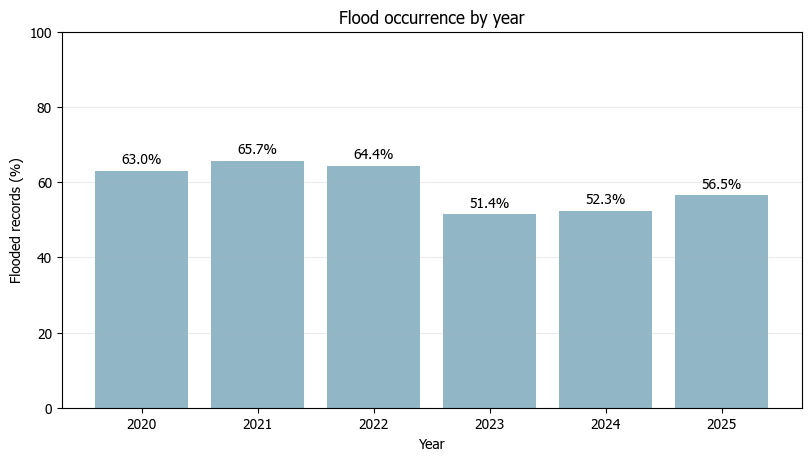

Yearly flood rates (descriptive only; model split is by complete months below):


,total_records,flooded_records,flooded_rate
year,,,
2020,216,136,0.630
2021,216,142,0.657
2022,216,139,0.644
2023,216,111,0.514
2024,216,113,0.523
2025,216,122,0.565


In [86]:
year_summary = data.groupby('year', as_index=False).agg(
    flooded_rate=('flooded', 'mean'),
    flooded_records=('flooded', 'sum'),
    total_records=('flooded', 'size'),
)
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
bars = ax.bar(year_summary['year'].astype(str), year_summary['flooded_rate'] * 100,
              color='#91B7C7')
ax.set(title='Flood occurrence by year', xlabel='Year', ylabel='Flooded records (%)', ylim=(0, 100))
ax.bar_label(bars, labels=[f'{v:.1f}%' for v in year_summary['flooded_rate'] * 100], padding=3)
ax.grid(axis='y', alpha=.25)
display(fig)
plt.close(fig)

print('Yearly flood rates (descriptive only; model split is by complete months below):')
display(year_summary.set_index('year')[['total_records', 'flooded_records', 'flooded_rate']].round(3))

## 3. สร้าง Features ที่ไม่ใช้ข้อมูลอนาคต

สร้าง lag จากเดือนก่อนหน้าภายในแต่ละอำเภอ และผลรวมฝนย้อนหลัง 3 เดือน โดยตัดแถวต้นช่วงที่ยังสร้าง lag 3 เดือนไม่ได้ออก เดือน/อำเภอเป็นข้อมูลที่ทราบล่วงหน้า ส่วนตัวแปร `flooded` ปัจจุบันเป็น target เท่านั้น ไม่ใส่ predictors กราฟท้ายหัวข้อนี้แสดงจำนวนแถวและช่วงเวลาของ Train/Validation/Test

Train: 816 แถว (69.6%; 48 เดือน, 2020-04 ถึง 2024-03) | ท่วม 527 (64.6%)
Validation: 170 แถว (14.5%; 10 เดือน, 2024-04 ถึง 2025-01) | ท่วม 98 (57.6%)
Test: 187 แถว (15.9%; 11 เดือน, 2025-02 ถึง 2025-12) | ท่วม 110 (58.8%)
Features: ['district', 'month_sin', 'month_cos', 'rain_total_lag1_mm', 'rain_daily_max_lag1_mm', 'humidity_lag1_pct', 'temperature_lag1_c', 'flooded_lag1', 'rain_prev3m_sum_mm', 'sea_level_mean_lag1']
ตัวแปรผลลัพธ์/ข้อมูลน้ำท่วมเดือนปัจจุบันที่ไม่ใช้เป็น feature: ['flooded', 'flood_status', 'max_flood_ha', 'flood_events_month', 'flood_windows']


,size,sum,mean
year,,,
2020,153,108,0.706
2021,204,142,0.696
2022,204,139,0.681
2023,204,111,0.544
2024,204,113,0.554
2025,204,122,0.598


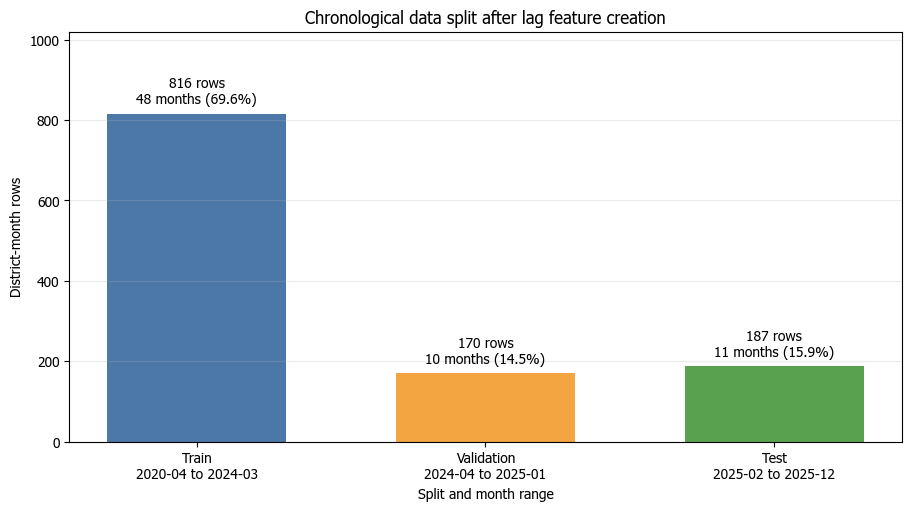

In [87]:
model_data = data.sort_values(['district_code', 'month_start']).copy()
by_district = model_data.groupby('district_code', sort=False)

lag_sources = {
    'rain_total_lag1_mm': 'monthly_rain_total_mm',
    'rain_daily_max_lag1_mm': 'monthly_rain_daily_max_mm',
    'humidity_lag1_pct': 'humidity_mean_rh_pct',
    'temperature_lag1_c': 'humidity_mean_temp_c',
    'flooded_lag1': 'flooded',
    'sea_level_mean_lag1': 'sea_level_monthly_mean',
}
for new_column, source_column in lag_sources.items():
    model_data[new_column] = by_district[source_column].shift(1)

model_data['rain_prev3m_sum_mm'] = by_district['monthly_rain_total_mm'].transform(
    lambda values: values.shift(1).rolling(window=3, min_periods=3).sum()
)
model_data['month_sin'] = np.sin(2 * np.pi * model_data['month'] / 12)
model_data['month_cos'] = np.cos(2 * np.pi * model_data['month'] / 12)

feature_columns = [
    'district', 'month_sin', 'month_cos', 'rain_total_lag1_mm',
    'rain_daily_max_lag1_mm', 'humidity_lag1_pct', 'temperature_lag1_c',
    'flooded_lag1', 'rain_prev3m_sum_mm', 'sea_level_mean_lag1',
]
target_column = 'flooded'
model_data = model_data.dropna(
    subset=[column for column in feature_columns if column != 'sea_level_mean_lag1'] + [target_column]
).copy()

ordered_months = np.sort(model_data['month_start'].unique())
n_months = len(ordered_months)
n_train_months = int(np.floor(n_months * 0.70))
n_validation_months = int(round(n_months * 0.15))
train_months = ordered_months[:n_train_months]
validation_months = ordered_months[n_train_months:n_train_months + n_validation_months]
test_months = ordered_months[n_train_months + n_validation_months:]

train = model_data.loc[model_data['month_start'].isin(train_months)].copy()
validation = model_data.loc[model_data['month_start'].isin(validation_months)].copy()
test = model_data.loc[model_data['month_start'].isin(test_months)].copy()
if train.empty or validation.empty or test.empty:
    raise ValueError('Train, Validation หรือ Test ว่าง กรุณาตรวจจำนวนเดือนและข้อมูล lag')
if not (train['month_start'].max() < validation['month_start'].min()
        and validation['month_start'].max() < test['month_start'].min()):
    raise ValueError('พบเดือนที่ทับซ้อนกันระหว่าง Train, Validation และ Test')

X_train, y_train = train[feature_columns], train[target_column].astype(int)
X_validation, y_validation = validation[feature_columns], validation[target_column].astype(int)
X_test, y_test = test[feature_columns], test[target_column].astype(int)
print(f'Train: {len(train)} แถว ({len(train_months) / n_months:.1%}; {len(train_months)} เดือน, {train["month_start"].min():%Y-%m} ถึง {train["month_start"].max():%Y-%m}) | ท่วม {y_train.sum()} ({y_train.mean():.1%})')
print(f'Validation: {len(validation)} แถว ({len(validation_months) / n_months:.1%}; {len(validation_months)} เดือน, {validation["month_start"].min():%Y-%m} ถึง {validation["month_start"].max():%Y-%m}) | ท่วม {y_validation.sum()} ({y_validation.mean():.1%})')
print(f'Test: {len(test)} แถว ({len(test_months) / n_months:.1%}; {len(test_months)} เดือน, {test["month_start"].min():%Y-%m} ถึง {test["month_start"].max():%Y-%m}) | ท่วม {y_test.sum()} ({y_test.mean():.1%})')
print('Features:', feature_columns)
print('ตัวแปรผลลัพธ์/ข้อมูลน้ำท่วมเดือนปัจจุบันที่ไม่ใช้เป็น feature:',
      ['flooded', 'flood_status', 'max_flood_ha', 'flood_events_month', 'flood_windows'])
display(model_data.groupby('year')[target_column].agg(['size', 'sum', 'mean']).round(3))

split_frames = {'Train': train, 'Validation': validation, 'Test': test}
split_colors = ['#4C78A8', '#F2A541', '#59A14F']
split_labels = []
split_row_counts = []
split_details = []
for split_name, split_frame in split_frames.items():
    start_month = split_frame['month_start'].min()
    end_month = split_frame['month_start'].max()
    month_count = split_frame['month_start'].nunique()
    split_labels.append(f'{split_name}\n{start_month:%Y-%m} to {end_month:%Y-%m}')
    split_row_counts.append(len(split_frame))
    split_details.append(f'{len(split_frame):,} rows\n{month_count} months ({month_count / n_months:.1%})')

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
split_bars = ax.bar(split_labels, split_row_counts, color=split_colors, width=0.62)
ax.bar_label(split_bars, labels=split_details, padding=5, fontsize=10)
ax.set(
    title='Chronological data split after lag feature creation',
    xlabel='Split and month range', ylabel='District-month rows',
    ylim=(0, max(split_row_counts) * 1.25),
)
ax.grid(axis='y', alpha=.25)
display(fig)
plt.close(fig)

## 4. ฝึก Baseline และเลือก Candidate Models ด้วย Walk-Forward Validation

ตาราง Validation แรกเป็นผลจากช่วงเดียว ใช้ดูประกอบเท่านั้น เพื่อเลือกโมเดลให้เสถียรขึ้น จะทำ Walk-Forward บนข้อมูลก่อน Test: ฝึกจากอดีตแล้วประเมิน 5 ช่วงถัดไป ช่วงละ 6 เดือน เลือกจาก Recall เฉลี่ยสูงสุดที่ threshold 0.5 และใช้ PR-AUC เฉลี่ยตัดสินเมื่อ Recall เท่ากัน ค่า std ในตารางสรุปบอกความแกว่งระหว่างช่วง ยิ่งต่ำยิ่งสม่ำเสมอ จากนั้นส่งโมเดลที่เลือกไปฝึกใหม่และประเมินบน Test ในหัวข้อ 5 โดย Test ไม่ถูกใช้เลือกโมเดลหรือ threshold

,accuracy,balanced_accuracy,precision,recall,f1,pr_auc,roc_auc
model,,,,,,,
Logistic Regression (baseline),0.876,0.874,0.897,0.888,0.892,0.976,0.966
Random Forest,0.882,0.883,0.915,0.878,0.896,0.936,0.941
XGBoost,0.882,0.883,0.915,0.878,0.896,0.940,0.919


,fold,period,model,recall,pr_auc
0,1,2022-08 to 2023-01,Logistic Regression (baseline),0.242,0.669
1,1,2022-08 to 2023-01,Random Forest,0.935,0.957
2,1,2022-08 to 2023-01,XGBoost,0.935,0.930
3,2,2023-02 to 2023-07,Logistic Regression (baseline),0.945,0.922
4,2,2023-02 to 2023-07,Random Forest,0.927,0.922
5,2,2023-02 to 2023-07,XGBoost,0.927,0.892
6,3,2023-08 to 2024-01,Logistic Regression (baseline),0.912,0.962
7,3,2023-08 to 2024-01,Random Forest,0.895,0.966
8,3,2023-08 to 2024-01,XGBoost,0.895,0.969
9,4,2024-02 to 2024-07,Logistic Regression (baseline),0.930,0.967


,mean_recall,std_recall,mean_pr_auc,std_pr_auc
model,,,,
Random Forest,0.909,0.032,0.935,0.025
XGBoost,0.909,0.032,0.927,0.028
Logistic Regression (baseline),0.785,0.304,0.897,0.129


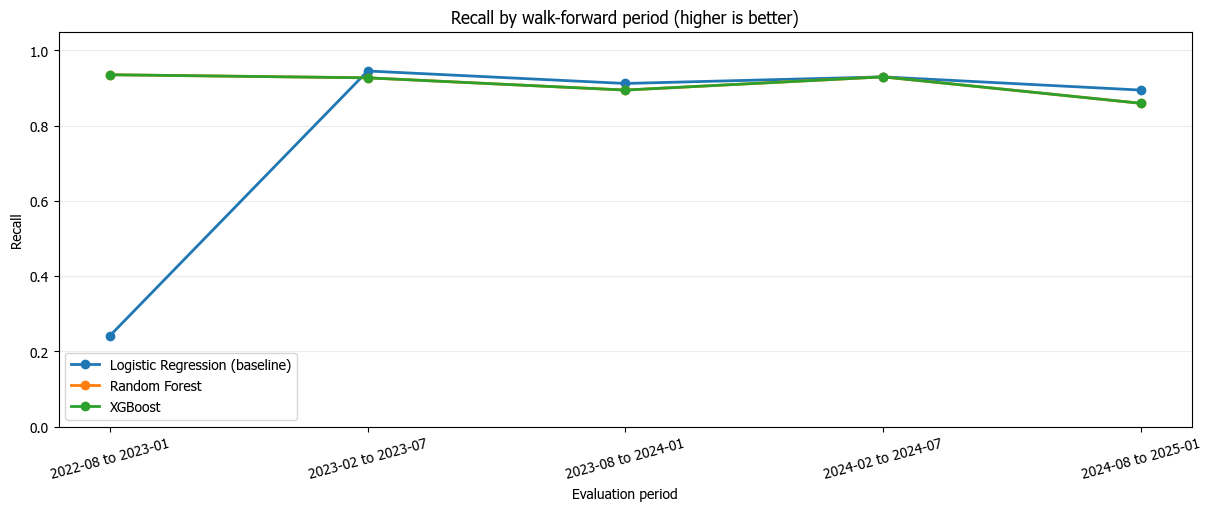

เลือกจาก Recall เฉลี่ยสูงสุดใน Walk-Forward (5 ช่วง, 6 เดือนต่อช่วง; PR-AUC เฉลี่ยใช้ตัดสินกรณี Recall เท่ากัน): Random Forest (Recall เฉลี่ย=0.909)


In [88]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, average_precision_score, roc_auc_score, ConfusionMatrixDisplay,
)

categorical_features = ['district']
numeric_features = [column for column in feature_columns if column not in categorical_features]

def make_preprocessor(scale_numeric):
    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale_numeric:
        numeric_steps.append(('scaler', StandardScaler()))
    return ColumnTransformer(
        transformers=[
            ('numeric', Pipeline(numeric_steps), numeric_features),
            ('district', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ],
        remainder='drop',
    )

models = {
    'Logistic Regression (baseline)': Pipeline([
        ('preprocess', make_preprocessor(scale_numeric=True)),
        ('model', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)),
    ]),
    'Random Forest': Pipeline([
        ('preprocess', make_preprocessor(scale_numeric=False)),
        ('model', RandomForestClassifier(
            n_estimators=400, min_samples_leaf=3, class_weight='balanced_subsample',
            max_features='sqrt', random_state=42, n_jobs=-1,
        )),
    ]),
    'XGBoost': Pipeline([
        ('preprocess', make_preprocessor(scale_numeric=False)),
        ('model', XGBClassifier(
            n_estimators=400, max_depth=3, learning_rate=0.03,
            subsample=0.9, colsample_bytree=0.9, min_child_weight=3,
            reg_lambda=1.0, scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
            eval_metric='logloss', random_state=42, n_jobs=-1,
        )),
    ]),
}

validation_results = []
for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    validation_predicted = pipeline.predict(X_validation)
    validation_probabilities = pipeline.predict_proba(X_validation)[:, 1]
    validation_results.append({
        'model': name,
        'accuracy': accuracy_score(y_validation, validation_predicted),
        'balanced_accuracy': balanced_accuracy_score(y_validation, validation_predicted),
        'precision': precision_score(y_validation, validation_predicted, zero_division=0),
        'recall': recall_score(y_validation, validation_predicted, zero_division=0),
        'f1': f1_score(y_validation, validation_predicted, zero_division=0),
        'pr_auc': average_precision_score(y_validation, validation_probabilities),
        'roc_auc': roc_auc_score(y_validation, validation_probabilities),
    })

validation_results_df = pd.DataFrame(validation_results).set_index('model')
display(validation_results_df.round(3))
pre_test = pd.concat([train, validation]).sort_values(['district_code', 'month_start'])
fold_months = np.sort(pre_test['month_start'].unique())
fold_size_months = 6
fold_count = min(5, (len(fold_months) - 24) // fold_size_months)
if fold_count < 2:
    raise ValueError('Walk-forward ต้องมีอย่างน้อย 36 เดือนก่อน Test เพื่อให้มี 24 เดือนฝึกเริ่มต้นและ 2 ช่วงประเมิน')

walk_forward = TimeSeriesSplit(n_splits=fold_count, test_size=fold_size_months)
walk_forward_results = []
for fold_number, (train_month_indices, validation_month_indices) in enumerate(
    walk_forward.split(fold_months), start=1
):
    fold_train_months = fold_months[train_month_indices]
    fold_validation_months = fold_months[validation_month_indices]
    fold_train = pre_test[pre_test['month_start'].isin(fold_train_months)]
    fold_validation = pre_test[pre_test['month_start'].isin(fold_validation_months)]
    X_fold_train = fold_train[feature_columns]
    y_fold_train = fold_train[target_column].astype(int)
    X_fold_validation = fold_validation[feature_columns]
    y_fold_validation = fold_validation[target_column].astype(int)
    fold_positive_count = int((y_fold_train == 1).sum())
    if fold_positive_count == 0:
        raise ValueError(f'Walk-forward fold {fold_number} ไม่มีตัวอย่างน้ำท่วมในข้อมูลฝึก')
    if int((y_fold_validation == 1).sum()) == 0:
        raise ValueError(f'Walk-forward fold {fold_number} ไม่มีตัวอย่างน้ำท่วมในช่วงประเมิน')

    for name, prototype in models.items():
        fold_model = clone(prototype)
        if name == 'XGBoost':
            fold_model.set_params(
                model__scale_pos_weight=(y_fold_train == 0).sum() / fold_positive_count
            )
        fold_model.fit(X_fold_train, y_fold_train)
        fold_predicted = fold_model.predict(X_fold_validation)
        fold_probabilities = fold_model.predict_proba(X_fold_validation)[:, 1]
        walk_forward_results.append({
            'fold': fold_number,
            'period': (
                f'{pd.Timestamp(fold_validation_months[0]):%Y-%m} to '
                f'{pd.Timestamp(fold_validation_months[-1]):%Y-%m}'
            ),
            'model': name,
            'recall': recall_score(y_fold_validation, fold_predicted, zero_division=0),
            'pr_auc': average_precision_score(y_fold_validation, fold_probabilities),
        })

walk_forward_results_df = pd.DataFrame(walk_forward_results)
walk_forward_summary_df = walk_forward_results_df.groupby('model').agg(
    mean_recall=('recall', 'mean'),
    std_recall=('recall', 'std'),
    mean_pr_auc=('pr_auc', 'mean'),
    std_pr_auc=('pr_auc', 'std'),
).sort_values(['mean_recall', 'mean_pr_auc'], ascending=[False, False])
display(walk_forward_results_df.round(3))
display(walk_forward_summary_df.round(3))
fold_period_labels = (
    walk_forward_results_df[walk_forward_results_df['model'] == next(iter(models))]
    .sort_values('fold')['period']
)
fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
for name in models:
    fold_values = walk_forward_results_df[walk_forward_results_df['model'] == name].sort_values('fold')
    ax.plot(fold_values['fold'], fold_values['recall'], marker='o', linewidth=2, label=name)
ax.set(
    title='Recall by walk-forward period (higher is better)',
    xlabel='Evaluation period', ylabel='Recall', ylim=(0, 1.05),
    xticks=range(1, fold_count + 1), xticklabels=fold_period_labels,
)
ax.tick_params(axis='x', labelrotation=15)
ax.grid(axis='y', alpha=.25)
ax.legend()
display(fig)
plt.close(fig)
selected_model_name = walk_forward_summary_df.index[0]
print(
    f'เลือกจาก Recall เฉลี่ยสูงสุดใน Walk-Forward ({fold_count} ช่วง, '
    f'{fold_size_months} เดือนต่อช่วง; PR-AUC เฉลี่ยใช้ตัดสินกรณี Recall เท่ากัน): '
    f'{selected_model_name} (Recall เฉลี่ย={walk_forward_summary_df.iloc[0]["mean_recall"]:.3f})'
)

# Keep the final Test period untouched until section 5.
X_pre_test = pre_test[feature_columns]
y_pre_test = pre_test[target_column].astype(int)
selected_model = models[selected_model_name]

### กราฟเปรียบเทียบโมเดลทั้ง 3 ตัว

กราฟด้านล่างเปรียบเทียบคะแนนทั้ง 7 metrics ของ Logistic Regression, Random Forest และ XGBoost บน Validation ช่วงเดียว เพื่อดูประกอบ ส่วนการเลือกโมเดลใช้ Recall เฉลี่ยจาก Walk-Forward ที่ threshold 0.5 และใช้ PR-AUC เฉลี่ยตัดสินเมื่อ Recall เท่ากัน ไม่ได้ใช้ชุด Test ในการเลือก

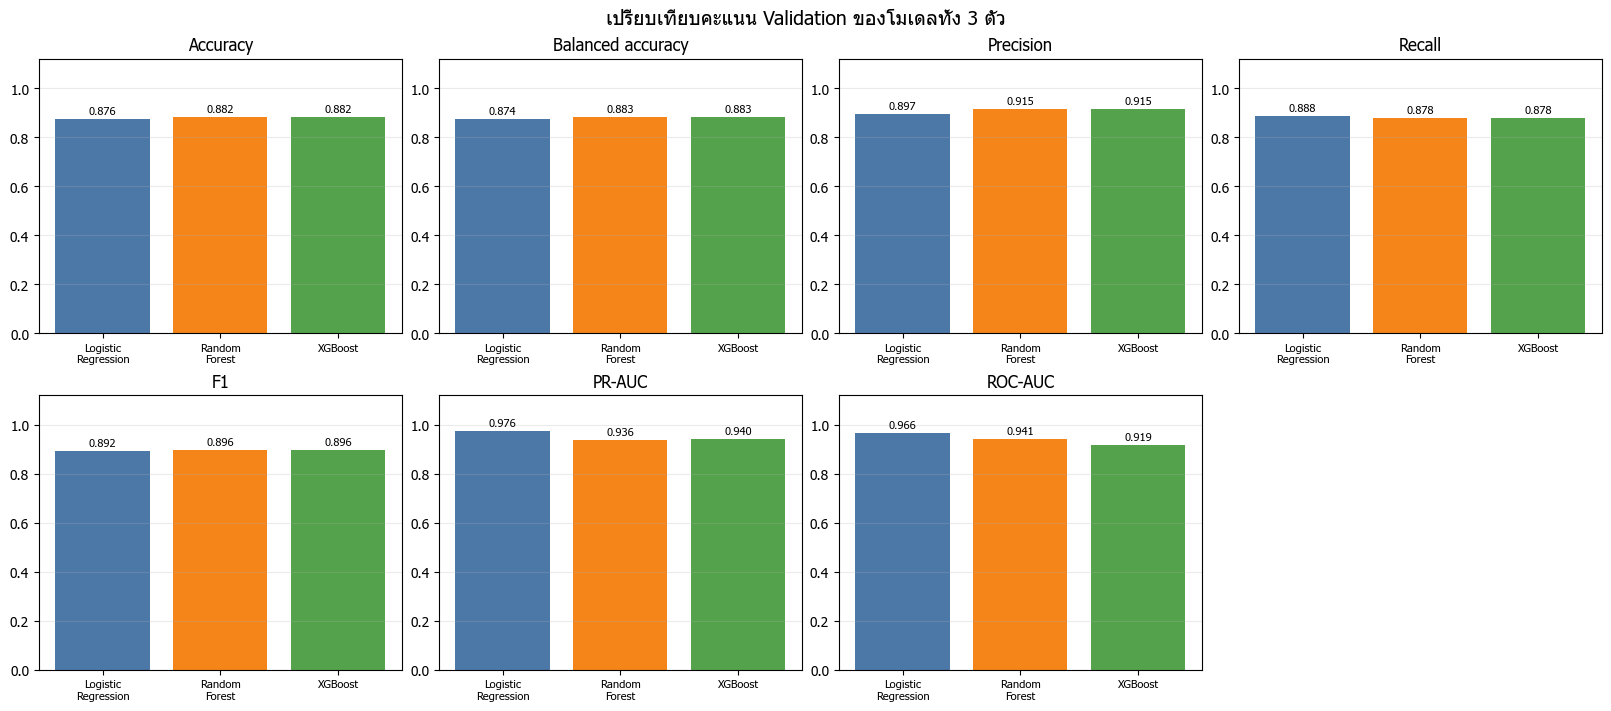

In [89]:
metric_labels = {
    'accuracy': 'Accuracy',
    'balanced_accuracy': 'Balanced accuracy',
    'precision': 'Precision',
    'recall': 'Recall',
    'f1': 'F1',
    'pr_auc': 'PR-AUC',
    'roc_auc': 'ROC-AUC',
}
model_labels = {
    'Logistic Regression (baseline)': 'Logistic\nRegression',
    'Random Forest': 'Random\nForest',
    'XGBoost': 'XGBoost',
}
model_colors = ['#4C78A8', '#F58518', '#54A24B']

plt.rcParams['font.family'] = 'Tahoma'
fig, axes = plt.subplots(2, 4, figsize=(16, 7), constrained_layout=True)
for ax, (metric, label) in zip(axes.flat, metric_labels.items()):
    values = validation_results_df[metric]
    bars = ax.bar(
        [model_labels[name] for name in values.index],
        values.values,
        color=model_colors,
    )
    ax.bar_label(bars, labels=[f'{value:.3f}' for value in values], padding=2, fontsize=8)
    ax.set_title(label)
    ax.set_ylim(0, 1.12)
    ax.tick_params(axis='x', labelsize=8)
    ax.grid(axis='y', alpha=0.25)

axes.flat[-1].set_visible(False)
fig.suptitle('เปรียบเทียบคะแนน Validation ของโมเดลทั้ง 3 ตัว', fontsize=14)
display(fig)
plt.close(fig)

## 5. ประเมินโมเดลที่เลือกบน Test ช่วงท้าย

หลังเลือกโมเดลจาก Walk-Forward บนข้อมูลก่อน Test แล้ว ฝึกโมเดลที่เลือกใหม่ด้วย Train+Validation และประเมินบน Test ช่วงท้ายเพียงครั้งเดียวด้วย threshold 0.5 รายงาน 7 metrics และ Confusion Matrix ของโมเดลที่เลือก โดยไม่ทดสอบโมเดลที่ไม่ได้เลือก

,accuracy,balanced_accuracy,precision,recall,f1,pr_auc,roc_auc
Random Forest,0.85,0.844,0.866,0.882,0.874,0.95,0.936


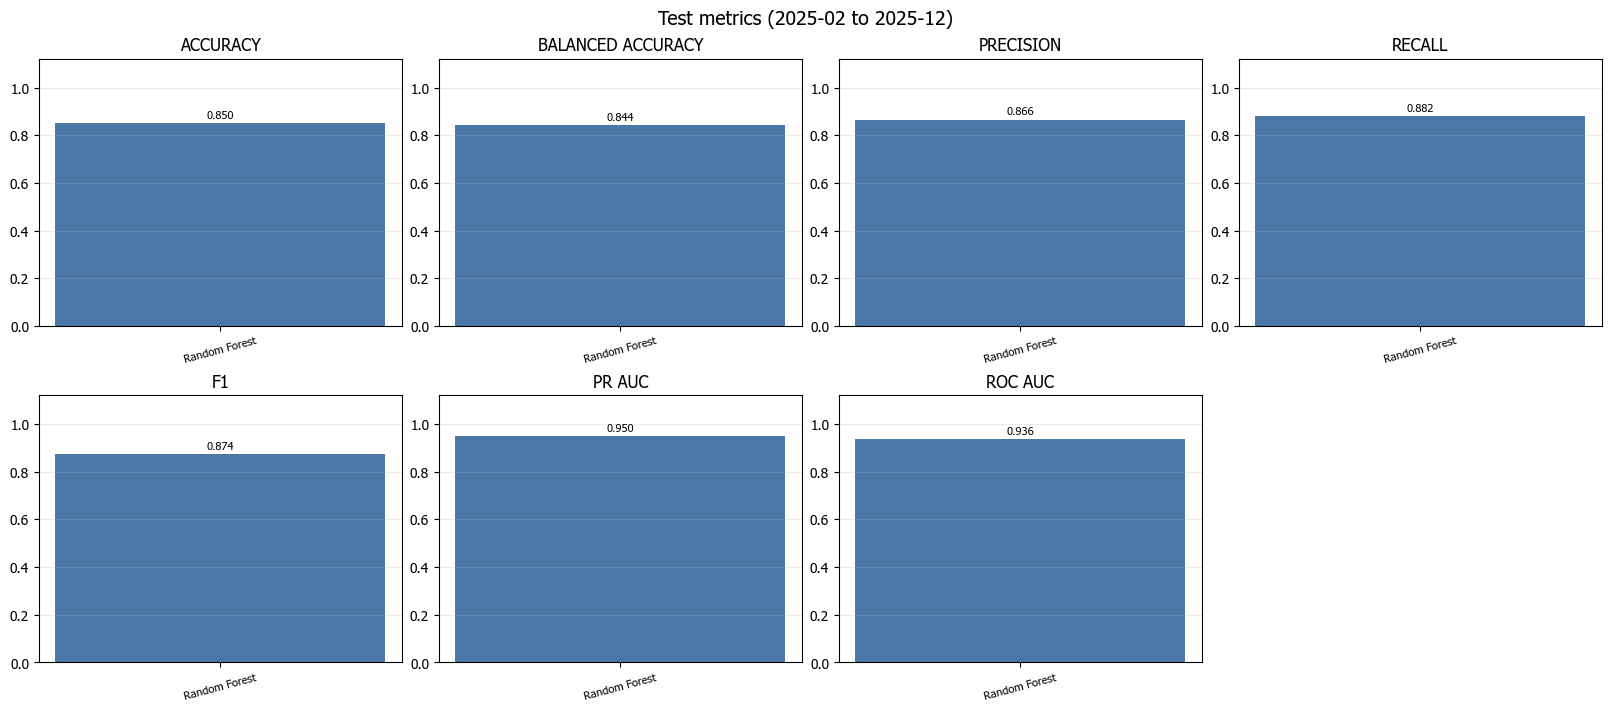

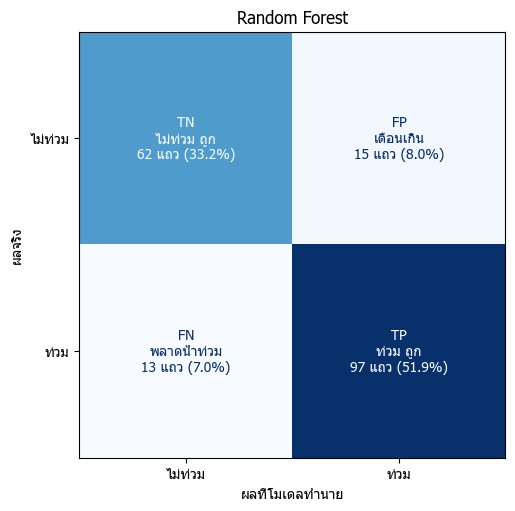

Selected model: Random Forest | selected by walk-forward mean Recall; mean PR-AUC breaks ties
Test observations: 187 | actual flooded: 110 | actual not flooded: 77
Missed flooded cases (FN): 13
Confusion matrix colors: dark blue = more rows; light blue = fewer. Cells are TN (no flood, correct), FP (false alarm), FN (missed flood), TP (flood, correct); each shows count and percent of all test rows.
Test results are for final reporting only; model selection remains based on walk-forward results before Test.


In [90]:
plt.rcParams['font.family'] = 'Tahoma'
positive_count = int((y_pre_test == 1).sum())
if positive_count == 0:
    raise ValueError('ข้อมูลก่อน Test ไม่มีตัวอย่างน้ำท่วมสำหรับฝึกโมเดล')
if selected_model_name == 'XGBoost':
    selected_model.set_params(
        model__scale_pos_weight=(y_pre_test == 0).sum() / positive_count
    )
selected_model.fit(X_pre_test, y_pre_test)
test_predicted = selected_model.predict(X_test)
test_probabilities = selected_model.predict_proba(X_test)[:, 1]
predictions = {selected_model_name: (test_predicted, test_probabilities)}
test_results_df = pd.DataFrame([{
    'accuracy': accuracy_score(y_test, test_predicted),
    'balanced_accuracy': balanced_accuracy_score(y_test, test_predicted),
    'precision': precision_score(y_test, test_predicted, zero_division=0),
    'recall': recall_score(y_test, test_predicted, zero_division=0),
    'f1': f1_score(y_test, test_predicted, zero_division=0),
    'pr_auc': average_precision_score(y_test, test_probabilities),
    'roc_auc': roc_auc_score(y_test, test_probabilities),
}], index=[selected_model_name])
metric_columns = [
    'accuracy', 'balanced_accuracy', 'precision', 'recall', 'f1', 'pr_auc', 'roc_auc',
]
display(test_results_df.round(3))
fig, axes = plt.subplots(2, 4, figsize=(16, 7), constrained_layout=True)
for ax, metric in zip(axes.flat, metric_columns):
    values = test_results_df[metric]
    bars = ax.bar([selected_model_name], values.values, color='#4C78A8')
    ax.bar_label(bars, labels=[f'{value:.3f}' for value in values], padding=2, fontsize=8)
    ax.set_title(metric.replace('_', ' ').upper())
    ax.set_ylim(0, 1.12)
    ax.tick_params(axis='x', labelsize=8, rotation=15)
    ax.grid(axis='y', alpha=.25)
axes.flat[-1].set_visible(False)
fig.suptitle(
    f'Test metrics ({test["month_start"].min():%Y-%m} to {test["month_start"].max():%Y-%m})',
    fontsize=14,
)
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
display_matrix = ConfusionMatrixDisplay.from_predictions(
    y_test, test_predicted, display_labels=['No flood', 'Flood'],
    values_format='d', colorbar=False, cmap='Blues', ax=ax,
)
matrix = display_matrix.confusion_matrix
total = matrix.sum()
for row in range(matrix.shape[0]):
    for column in range(matrix.shape[1]):
        count = matrix[row, column]
        cell_label = {
            (0, 0): 'TN\nไม่ท่วม ถูก',
            (0, 1): 'FP\nเตือนเกิน',
            (1, 0): 'FN\nพลาดน้ำท่วม',
            (1, 1): 'TP\nท่วม ถูก',
        }[(row, column)]
        display_matrix.text_[row, column].set_text(
            f'{cell_label}\n{count:,} แถว ({count / total:.1%})'
        )
ax.set_xlabel('ผลที่โมเดลทำนาย')
ax.set_ylabel('ผลจริง')
ax.set_xticklabels(['ไม่ท่วม', 'ท่วม'])
ax.set_yticklabels(['ไม่ท่วม', 'ท่วม'])
ax.set_title(selected_model_name)
display(fig)
plt.close(fig)

print('Selected model:', selected_model_name, '| selected by walk-forward mean Recall; mean PR-AUC breaks ties')
print('Test observations:', len(y_test), '| actual flooded:', int(y_test.sum()), '| actual not flooded:', int((y_test == 0).sum()))
print('Missed flooded cases (FN):', int(((y_test == 1) & (test_predicted == 0)).sum()))
print('Confusion matrix colors: dark blue = more rows; light blue = fewer. Cells are TN (no flood, correct), FP (false alarm), FN (missed flood), TP (flood, correct); each shows count and percent of all test rows.')
print('Test results are for final reporting only; model selection remains based on walk-forward results before Test.')

## 6. สรุปการทดลอง

โมเดลถูกเลือกจาก Recall เฉลี่ยในการทดสอบแบบ Walk-Forward บนข้อมูลก่อน Test ที่ threshold 0.5 (หาก Recall เฉลี่ยเท่ากัน ใช้ PR-AUC เฉลี่ยตัดสิน) แล้วฝึกใหม่ด้วย Train+Validation ก่อนประเมินครั้งสุดท้ายบน Test ช่วงท้าย ซึ่งไม่ได้ใช้เลือกโมเดลหรือ threshold ค่า Recall ช่วยวัดการจับเหตุการณ์น้ำท่วม ส่วน PR-AUC ใช้ประกอบการดูคุณภาพการจัดอันดับเมื่อคลาสมีสัดส่วนไม่เท่ากัน ผล Test มีเพียง 5 เดือนและเป็นช่วงเวลาหนึ่ง จึงควรเก็บข้อมูลหลายปีเพิ่มเติมเพื่อยืนยันผลก่อนใช้งานจริง

## 7. แสดงระดับความเสี่ยงน้ำท่วมรายเดือน และประมาณค่าเฉลี่ยรายวัน (แบบหยาบ)

โมเดลทำนายโอกาสที่อำเภอจะมีน้ำท่วม **อย่างน้อยหนึ่งครั้งในทั้งเดือน** ไม่ใช่โมเดลพยากรณ์รายวัน โดยแบ่งระดับตามโอกาสน้ำท่วมที่โมเดลประเมิน: **ต่ำ < 25%**, **ปานกลาง 25% ถึงน้อยกว่า 50%**, **สูง 50% ถึงน้อยกว่า 75%**, และ **สูงมากตั้งแต่ 75% ขึ้นไป** ส่วนคำตัดสินแบบท่วม/ไม่ท่วมที่ใช้ในตารางประเมินยังคงใช้เกณฑ์ 50% (ระดับสูงขึ้นไป = ท่วม) ระดับเหล่านี้เป็นเกณฑ์เพื่อช่วยอ่านผล ไม่ได้ยืนยันว่าเปอร์เซ็นต์เป็นความเสี่ยงจริงที่ผ่านการปรับเทียบแล้ว

คอลัมน์โอกาสเฉลี่ยต่อวันเป็นเพียงค่าประมาณจากโอกาสรายเดือน โดยสมมติว่าความเสี่ยงเท่ากันและเป็นอิสระในทุกวัน: `P(น้ำท่วมใน 1 วัน) = 1 - (1 - P(น้ำท่วมในเดือน)) ** (1 / จำนวนวันในเดือน)`. ค่านี้ไม่ได้ใช้สภาพอากาศของวันพรุ่งนี้ และความน่าจะเป็นรายวันจะเท่ากันทุกวันในเดือน ผลด้านล่างเป็น **การทดสอบย้อนหลังของเดือนล่าสุดในชุดทดสอบ** ไม่ใช่คำพยากรณ์ปัจจุบัน เพราะข้อมูลในไฟล์สิ้นสุดปี 2025

In [91]:
best_model_name = selected_model_name
monthly_probabilities = np.clip(predictions[best_model_name][1], 0, 1)

daily_estimate = test[['district', 'month_start', 'flooded']].copy()
daily_estimate = daily_estimate.rename(columns={'flooded': 'actual_flooded_month'})
daily_estimate['monthly_flood_probability_pct'] = monthly_probabilities * 100
daily_estimate['monthly_no_flood_probability_pct'] = (1 - monthly_probabilities) * 100
daily_estimate['predicted_monthly_risk_level'] = np.select(
    [monthly_probabilities < 0.25, monthly_probabilities < 0.50, monthly_probabilities < 0.75],
    ['ต่ำ', 'ปานกลาง', 'สูง'],
    default='สูงมาก',
)
daily_estimate['predicted_monthly_status'] = np.where(
    monthly_probabilities >= 0.5, 'ท่วมในเดือนนั้น', 'ไม่ท่วมในเดือนนั้น'
)
days_in_month = daily_estimate['month_start'].dt.days_in_month.to_numpy()
daily_estimate['one_day_equivalent_probability_pct'] = (
    1 - (1 - monthly_probabilities) ** (1 / days_in_month)
) * 100

latest_test_month = daily_estimate['month_start'].max()
latest_month_estimate = daily_estimate.loc[
    daily_estimate['month_start'].eq(latest_test_month)
].sort_values('monthly_flood_probability_pct', ascending=False)
print(f'โมเดลที่เลือกจาก Recall เฉลี่ยใน Walk-Forward: {best_model_name}')
print(f'ตัวอย่างเดือนล่าสุดในชุดทดสอบ: {latest_test_month:%Y-%m}')
print('ระดับความเสี่ยง: ต่ำ <25%; ปานกลาง 25-<50%; สูง 50-<75%; สูงมาก >=75%')
print('เกณฑ์ตัดสินท่วม/ไม่ท่วมยังคงเป็น 50%: ระดับสูงหรือสูงมาก = ท่วม; ระดับต่ำหรือปานกลาง = ไม่ท่วม')
display(latest_month_estimate[[
    'district', 'month_start', 'predicted_monthly_risk_level', 'predicted_monthly_status',
    'monthly_flood_probability_pct', 'monthly_no_flood_probability_pct',
    'one_day_equivalent_probability_pct',
    'actual_flooded_month',
]].rename(columns={
    'district': 'อำเภอ',
    'month_start': 'เดือน',
    'predicted_monthly_risk_level': 'ระดับความเสี่ยง',
    'predicted_monthly_status': 'ผลตัดสินท่วม/ไม่ท่วม (เกณฑ์ 50%)',
    'monthly_flood_probability_pct': 'โอกาสท่วมทั้งเดือน (%)',
    'monthly_no_flood_probability_pct': 'โอกาสไม่ท่วมทั้งเดือน (%)',
    'one_day_equivalent_probability_pct': 'โอกาสเฉลี่ยต่อวันโดยประมาณ (%)',
    'actual_flooded_month': 'ผลจริงในเดือน',
}).round({
    'monthly_flood_probability_pct': 1,
    'monthly_no_flood_probability_pct': 1,
    'one_day_equivalent_probability_pct': 2,
}))

โมเดลที่เลือกจาก Recall เฉลี่ยใน Walk-Forward: Random Forest
ตัวอย่างเดือนล่าสุดในชุดทดสอบ: 2025-12
ระดับความเสี่ยง: ต่ำ <25%; ปานกลาง 25-<50%; สูง 50-<75%; สูงมาก >=75%
เกณฑ์ตัดสินท่วม/ไม่ท่วมยังคงเป็น 50%: ระดับสูงหรือสูงมาก = ท่วม; ระดับต่ำหรือปานกลาง = ไม่ท่วม


,อำเภอ,เดือน,ระดับความเสี่ยง,ผลตัดสินท่วม/ไม่ท่วม (เกณฑ์ 50%),โอกาสท่วมทั้งเดือน (%),โอกาสไม่ท่วมทั้งเดือน (%),โอกาสเฉลี่ยต่อวันโดยประมาณ (%),ผลจริงในเดือน
359,Hua Sai,2025-12-01,สูงมาก,ท่วมในเดือนนั้น,99.136187,0.863813,14.210746,1
287,Chian Yai,2025-12-01,สูงมาก,ท่วมในเดือนนั้น,98.781420,1.218580,13.253222,1
791,Pak Phanang,2025-12-01,สูงมาก,ท่วมในเดือนนั้น,97.998446,2.001554,11.853434,1
143,Cha-uat,2025-12-01,สูงมาก,ท่วมในเดือนนั้น,97.194226,2.805774,10.887796,1
647,Muang Nakhon Si Thammarat,2025-12-01,สูงมาก,ท่วมในเดือนนั้น,95.744872,4.255128,9.682610,1
1007,Ron Phibun,2025-12-01,สูงมาก,ท่วมในเดือนนั้น,93.856897,6.143103,8.606410,1
1151,Tha Sala,2025-12-01,สูงมาก,ท่วมในเดือนนั้น,93.764002,6.235998,8.562151,1
1295,Thung Yai,2025-12-01,สูงมาก,ท่วมในเดือนนั้น,91.411620,8.588380,7.613175,0
215,Chawang,2025-12-01,สูงมาก,ท่วมในเดือนนั้น,90.334882,9.665118,7.260501,1
431,Khanom,2025-12-01,สูงมาก,ท่วมในเดือนนั้น,89.524054,10.475946,7.019189,1
